<a href="https://colab.research.google.com/github/Cloud-Architect-Emma/minillm-research-lab/blob/main/03_train_minigpt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Selected device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )
else:
    print("Using CPU for training")


PyTorch version: 2.14.1+cu130
CUDA available: True
Selected device: cuda
GPU: Tesla T4


In [2]:

from pathlib import Path
from urllib.request import urlretrieve
import random
import numpy as np
import time
import json

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

data_path = data_dir / "tiny_shakespeare.txt"

url = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/"
    "tinyshakespeare/input.txt"
)

if not data_path.exists():
    urlretrieve(url, data_path)

text = data_path.read_text(encoding="utf-8")

chars = sorted(set(text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

all_tokens = torch.tensor(
    encode(text),
    dtype=torch.long
)

split = int(0.9 * len(all_tokens))

train_data = all_tokens[:split]
val_data = all_tokens[split:]

print("Vocabulary size:", vocab_size)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))

assert decode(encode("Hello")) == "Hello"
assert len(train_data) > len(val_data)

print("PASS: Dataset and tokenizer ready")


Vocabulary size: 65
Training tokens: 1003854
Validation tokens: 111540
PASS: Dataset and tokenizer ready


In [3]:

block_size = 32
n_embd = 64
n_head = 4
n_layer = 2
dropout = 0.1

batch_size = 32
learning_rate = 3e-4
weight_decay = 0.01

max_steps = 500
eval_interval = 100
eval_batches = 20

assert n_embd % n_head == 0
assert len(train_data) > block_size
assert len(val_data) > block_size

print("Device:", device)
print("Batch size:", batch_size)
print("Training steps:", max_steps)
print("Learning rate:", learning_rate)


Device: cuda
Batch size: 32
Training steps: 500
Learning rate: 0.0003


In [4]:

import torch.nn as nn
import torch.nn.functional as F

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(
            n_embd, head_size, bias=False
        )
        self.query = nn.Linear(
            n_embd, head_size, bias=False
        )
        self.value = nn.Linear(
            n_embd, head_size, bias=False
        )

        self.register_buffer(
            "tril",
            torch.tril(
                torch.ones(block_size, block_size)
            )
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)
        v = self.value(x)

        scores = (
            q @ k.transpose(-2, -1)
        ) * (k.shape[-1] ** -0.5)

        scores = scores.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        weights = F.softmax(
            scores, dim=-1
        )

        weights = self.dropout(weights)

        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()

        self.heads = nn.ModuleList([
            Head(head_size)
            for _ in range(num_heads)
        ])

        self.proj = nn.Linear(
            num_heads * head_size, n_embd
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        combined = torch.cat(
            [head(x) for head in self.heads],
            dim=-1
        )

        return self.dropout(
            self.proj(combined)
        )


class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self):
        super().__init__()

        head_size = n_embd // n_head

        self.sa = MultiHeadAttention(
            n_head, head_size
        )

        self.ffwd = FeedForward()

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )

        self.blocks = nn.Sequential(
            *[Block() for _ in range(n_layer)]
        )

        self.ln_f = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(
            n_embd, vocab_size
        )

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > block_size:
            raise ValueError(
                "Input exceeds context window"
            )

        token_embeddings = (
            self.token_embedding_table(idx)
        )

        position_embeddings = (
            self.position_embedding_table(
                torch.arange(
                    T, device=idx.device
                )
            )
        )

        x = token_embeddings + position_embeddings

        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )

        return logits, loss


model = MiniGPT().to(device)

parameter_count = sum(
    p.numel() for p in model.parameters()
)

print("MiniGPT model created")
print("Trainable parameters:", parameter_count)
print("Device:", device)


MiniGPT model created
Trainable parameters: 110145
Device: cuda


In [5]:

def get_batch(split_name):
    data = (
        train_data
        if split_name == "train"
        else val_data
    )

    starts = torch.randint(
        0,
        len(data) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size]
        for i in starts
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1]
        for i in starts
    ])

    return x.to(device), y.to(device)


xb, yb = get_batch("train")

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)

assert xb.shape == (batch_size, block_size)
assert yb.shape == (batch_size, block_size)
assert torch.equal(xb[:, 1:], yb[:, :-1])

print("PASS: Batch generator works")


Input batch shape: torch.Size([32, 32])
Target batch shape: torch.Size([32, 32])
PASS: Batch generator works


In [6]:

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

print("Optimiser: AdamW")
print("Learning rate:", learning_rate)
print("Weight decay:", weight_decay)


Optimiser: AdamW
Learning rate: 0.0003
Weight decay: 0.01


In [7]:

@torch.no_grad()
def estimate_loss():
    results = {}

    model.eval()

    for split_name in ["train", "val"]:
        losses = []

        for _ in range(eval_batches):
            x, y = get_batch(split_name)

            logits, loss = model(x, y)

            losses.append(loss.item())

        results[split_name] = (
            sum(losses) / len(losses)
        )

    model.train()

    return results


initial_losses = estimate_loss()

print("Initial training loss:",
      round(initial_losses["train"], 4))

print("Initial validation loss:",
      round(initial_losses["val"], 4))


Initial training loss: 4.2791
Initial validation loss: 4.3001


In [8]:

import math

artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)

history = []

def save_checkpoint(path, step, train_loss, val_loss):
    checkpoint = {
        "step": step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "config": {
            "vocab_size": vocab_size,
            "block_size": block_size,
            "n_embd": n_embd,
            "n_head": n_head,
            "n_layer": n_layer,
            "dropout": dropout,
            "learning_rate": learning_rate,
            "weight_decay": weight_decay,
            "batch_size": batch_size
        },
        "chars": chars
    }

    torch.save(checkpoint, path)


save_checkpoint(
    artifact_dir / "baseline.pt",
    0,
    initial_losses["train"],
    initial_losses["val"]
)

print("Baseline checkpoint saved!")


Baseline checkpoint saved!


In [9]:

start_time = time.perf_counter()

best_val_loss = float("inf")

for step in range(1, max_steps + 1):
    model.train()

    xb, yb = get_batch("train")

    # 1. Clear old gradients
    optimizer.zero_grad(set_to_none=True)

    # 2. Forward pass
    logits, loss = model(xb, yb)

    # 3. Backpropagation
    loss.backward()

    # 4. Update weights
    optimizer.step()

    # 5. Periodically evaluate
    if step == 1 or step % eval_interval == 0:
        losses = estimate_loss()

        train_loss = losses["train"]
        val_loss = losses["val"]

        elapsed = time.perf_counter() - start_time

        history.append({
            "step": step,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "elapsed_seconds": elapsed
        })

        print(
            f"Step {step:4d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Elapsed: {elapsed:.1f}s"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            save_checkpoint(
                artifact_dir / "best_model.pt",
                step,
                train_loss,
                val_loss
            )

# Save the final training state
final_losses = estimate_loss()

save_checkpoint(
    artifact_dir / "final_model.pt",
    max_steps,
    final_losses["train"],
    final_losses["val"]
)

total_time = time.perf_counter() - start_time

print("\nTraining finished!")
print("Total time (seconds):", round(total_time, 1))
print("Best validation loss:", round(best_val_loss, 4))


Step    1 | Train loss: 4.2441 | Val loss: 4.2617 | Elapsed: 0.4s
Step  100 | Train loss: 3.1209 | Val loss: 3.1862 | Elapsed: 2.1s
Step  200 | Train loss: 2.8097 | Val loss: 2.8202 | Elapsed: 4.3s
Step  300 | Train loss: 2.6391 | Val loss: 2.6546 | Elapsed: 6.2s
Step  400 | Train loss: 2.5401 | Val loss: 2.5549 | Elapsed: 8.0s
Step  500 | Train loss: 2.4998 | Val loss: 2.5155 | Elapsed: 9.7s

Training finished!
Total time (seconds): 9.9
Best validation loss: 2.5155


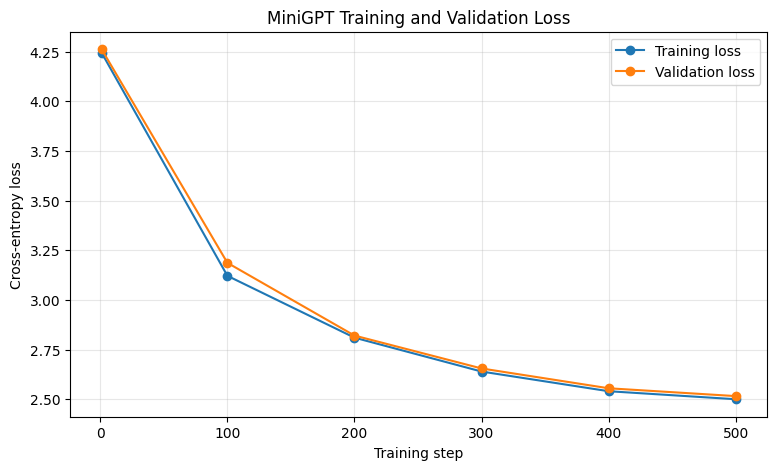

In [10]:

import matplotlib.pyplot as plt

steps = [row["step"] for row in history]

train_losses = [
    row["train_loss"] for row in history
]

val_losses = [
    row["val_loss"] for row in history
]

plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    train_losses,
    label="Training loss",
    marker="o"
)

plt.plot(
    steps,
    val_losses,
    label="Validation loss",
    marker="o"
)

plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("MiniGPT Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    artifact_dir / "training_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [11]:

validation_perplexity = math.exp(
    final_losses["val"]
)

print(
    "Final validation loss:",
    round(final_losses["val"], 4)
)

print(
    "Final validation perplexity:",
    round(validation_perplexity, 2)
)


Final validation loss: 2.5119
Final validation perplexity: 12.33


In [12]:

@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=200):
    model.eval()

    idx = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]

        logits, _ = model(idx_cond)

        last_logits = logits[:, -1, :]

        probabilities = F.softmax(
            last_logits,
            dim=-1
        )

        next_token = torch.multinomial(
            probabilities,
            num_samples=1
        )

        idx = torch.cat(
            (idx, next_token),
            dim=1
        )

    return decode(idx[0].tolist())


print("Text generation function ready!")


Text generation function ready!


In [13]:

torch.manual_seed(123)

prompt = "The "

trained_output = generate_text(
    model,
    prompt=prompt,
    max_new_tokens=300
)

print("TRAINED MODEL OUTPUT")
print("--------------------")
print(trained_output)


TRAINED MODEL OUTPUT
--------------------
The ther illy Co,Ysin haXNor p. Heriulobl outan RCUHurrve ale, t dE he?
Ge wenathse.

EUCUL:
$d IVEn INELl Toris thecank, arel'dathureyPo! mon s thoyo, n dis?
Aehmyougt hout I aindaor, ans ce y:

Sigrad?

SQasthefour fouf. IYes?

Diiay yeritherve anor thacou gn I Poor.
Dosce becy eerexsacatound hisold I


In [14]:

baseline_model = MiniGPT().to(device)

baseline_checkpoint = torch.load(
    artifact_dir / "baseline.pt",
    map_location=device,
    weights_only=True
)

baseline_model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)

torch.manual_seed(123)

baseline_output = generate_text(
    baseline_model,
    prompt="The ",
    max_new_tokens=300
)

torch.manual_seed(123)

trained_output = generate_text(
    model,
    prompt="The ",
    max_new_tokens=300
)

print("=== BEFORE TRAINING ===")
print(baseline_output)

print("\n=== AFTER TRAINING ===")
print(trained_output)


=== BEFORE TRAINING ===
The  oqCrAzuUyCi,YpiJ uRXNOrBo.HHeRfu.ublroMu!D;RCUHr?Hv$GPjk,JtUdE .!?EZ;i QnXLQs?.
bvckqLkf$dZZVgnnZUdnlrdu$-QvN3IcL!k,Ra3Ql'ubzzj&hxPS!LFQUSZ.tULyo,WCZd3.?.Vehm-3MqtfOvSUi. PiLdaoUVJXJ.!c;Oy:brlxRj:d?f
jQdxtlILT.aSf..Z.SxYejRzjDii yNUkMzXP$ULKYa;iwk3.Q;&k;QnEInPgg,jLD.$Cskbbcylec$Hxx-Y.JLsJA3&XPdjjQI

=== AFTER TRAINING ===
The ther illy Co,Ysin haXNor p. Heriulobl outan RCUHurrve ale, t dE he?
Ge wenathse.

EUCUL:
$d IVEn INELl Toris thecank, arel'dathureyPo! mon s thoyo, n dis?
Aehmyougt hout I aindaor, ans ce y:

Sigrad?

SQasthefour fouf. IYes?

Diiay yeritherve anor thacou gn I Poor.
Dosce becy eerexsacatound hisold I


In [15]:

model.eval()

test_x, test_y = get_batch("val")

with torch.no_grad():
    test_logits, test_loss = model(
        test_x, test_y
    )

assert test_logits.shape == (
    batch_size,
    block_size,
    vocab_size
)

assert torch.isfinite(test_loss)

for parameter in model.parameters():
    assert torch.isfinite(parameter).all()

print("PASS: Output dimensions correct")
print("PASS: Validation loss is finite")
print("PASS: Model parameters are finite")

print("\nALL LAB 3 MODEL TESTS PASSED")


PASS: Output dimensions correct
PASS: Validation loss is finite
PASS: Model parameters are finite

ALL LAB 3 MODEL TESTS PASSED


In [16]:

best_checkpoint = torch.load(
    artifact_dir / "best_model.pt",
    map_location=device,
    weights_only=True
)

restored_model = MiniGPT().to(device)

restored_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

restored_model.eval()

with torch.no_grad():
    original_logits, _ = model(test_x)

    restored_logits, _ = restored_model(test_x)

print(
    "Best checkpoint step:",
    best_checkpoint["step"]
)

print(
    "Best recorded validation loss:",
    round(best_checkpoint["val_loss"], 4)
)

print(
    "Final model and best model identical:",
    torch.allclose(
        original_logits,
        restored_logits,
        atol=1e-6
    )
)

print("PASS: Best checkpoint restored successfully")


Best checkpoint step: 500
Best recorded validation loss: 2.5155
Final model and best model identical: True
PASS: Best checkpoint restored successfully


In [17]:

second_restored_model = MiniGPT().to(device)

second_restored_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

second_restored_model.eval()

with torch.no_grad():
    first_logits, _ = restored_model(test_x)

    second_logits, _ = second_restored_model(test_x)

assert torch.allclose(
    first_logits,
    second_logits,
    atol=1e-6
)

print("PASS: Checkpoint predictions reproduced")


PASS: Checkpoint predictions reproduced


In [18]:

import pandas as pd

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

history_df = pd.DataFrame(history)

history_df.to_csv(
    results_dir / "training_metrics.csv",
    index=False
)

experiment_config = {
    "dataset": "Tiny Shakespeare",
    "tokenizer": "character-level",
    "seed": 42,
    "device": device,
    "vocab_size": vocab_size,
    "block_size": block_size,
    "n_embd": n_embd,
    "n_head": n_head,
    "n_layer": n_layer,
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "weight_decay": weight_decay,
    "max_steps": max_steps,
    "eval_interval": eval_interval,
    "eval_batches": eval_batches,
    "parameter_count": parameter_count,
    "initial_val_loss": initial_losses["val"],
    "final_val_loss": final_losses["val"],
    "best_sampled_val_loss": best_val_loss,
    "training_elapsed_seconds": total_time,
    "pytorch_version": torch.__version__
}

with open(
    results_dir / "experiment_config.json",
    "w"
) as f:
    json.dump(experiment_config, f, indent=2)

print("Experiment metrics exported!")
display(history_df)


Experiment metrics exported!


,step,train_loss,val_loss,elapsed_seconds
0,1,4.244076,4.261718,0.429276
1,100,3.120937,3.186243,2.117256
2,200,2.809709,2.820176,4.348118
3,300,2.639094,2.654617,6.229786
4,400,2.540072,2.554887,7.966100
5,500,2.499766,2.515474,9.685297


In [19]:

import shutil
from google.colab import files

shutil.make_archive(
    "minillm_lab3_artifacts",
    "zip",
    root_dir=".",
    base_dir="artifacts"
)

shutil.make_archive(
    "minillm_lab3_results",
    "zip",
    root_dir=".",
    base_dir="results"
)

files.download("minillm_lab3_artifacts.zip")
files.download("minillm_lab3_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>